# Relatório de Aplicação: Inferência Dinâmica e Interpretabilidade Física de EPBs

**Autor:** Alberto Ivo Vieira

---

## Resumo (Abstract)
Este relatório demonstra a viabilidade operacional do Sistema Automatizado de Detecção de Bolhas de Plasma Equatorial (EPBs). Diferente da etapa de avaliação teórica com divisão Treino/Teste, esta seção reproduz o cenário real de operação em um observatório de Clima Espacial: imagens brutas coletadas por um *All-Sky Imager* (ASI) são processadas cronologicamente pelo modelo mais recente.

Abaixo, exploramos o algoritmo de ponta a ponta: desde a extração de características (Reconstrução), interpretação espacial da decisão (SHAP), até o monitoramento sequencial de noites inteiras (com e sem ocorrência de bolhas).


## 1. Carregamento Dinâmico do Modelo V3

Em um ambiente de produção, o sistema varre a pasta de modelos e carrega dinamicamente a versão mais atualizada (o *checkpoint* de maior estabilidade). Neste caso, procuraremos iterativamente pela versão mais recente salva.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import glob
import os
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Importa as funções essenciais do sistema
from epb_detection_system import (
    load_model, 
    preprocess_epb_image, 
    analyze_temporal_sequence, 
    explain_shap_importance,
    load_epb_dataset,
    explain_feature_importance_3 as explain_features
)

# 1. Carrega dinamicamente o último modelo treinado
model_files = glob.glob('models/epb_recognition_model-v*.pkl')
if not model_files:
    raise FileNotFoundError("Nenhum modelo encontrado no diretório 'models/'.")

latest_model_path = sorted(model_files)[-1]
print(f"📡 Carregando sistema de produção: {latest_model_path}")

model_data = load_model(latest_model_path)
system = model_data.system
target_size = model_data.target_size

print(f" ✓ Módulo 2DPCA ativado com {system.n_components} componentes.")
print(f" ✓ Stacking Classifier inicializado e pronto para inferência.")


📡 Carregando sistema de produção: models/epb_recognition_model-v3.0.pkl
 ✓ Módulo 2DPCA ativado com 5 componentes.
 ✓ Stacking Classifier inicializado e pronto para inferência.


## 2. Avaliação de Desempenho Global e Matriz de Confusão

Para comprovar estatística e matematicamente o desempenho global do modelo, superando a análise de exemplos pontuais, avaliamos o sistema sobre todo o conjunto de testes ($X_{test}$). Abaixo, são geradas a Curva ROC, a Matriz de Confusão e o Relatório de Classificação (Precision, Recall e F1-Score). Estas métricas globais estabelecem o rigor científico do classificador adotado.

In [2]:
from epb_detection_system import plot_2dpca_variance, plot_confusion_matrix_analysis, plot_performance_metrics, load_epb_dataset, temporal_train_test_split
import matplotlib.pyplot as plt

# Carrega o dataset completo para avaliação global
print("Carregando dataset para métricas globais...")
images, labels, filenames = load_epb_dataset(
    data_folder='data/all-images',
    label_file='data/epb_labels.csv',
    target_size=target_size,
    apply_preprocessing=True
)

# Separa em treino e teste 
X_train, X_test, y_train, y_test, files_train, filenames_test = temporal_train_test_split(
    images, labels, filenames, test_size=0.25
)

y_proba = system.predict_proba(X_test)
y_pred = system.predict(X_test) 

Carregando dataset para métricas globais...


### 2.1 Análise de Variância (2DPCA)

Antes de analisar a classificação, é fundamental entender a representação dos dados. O gráfico abaixo mostra a importância (variância explicada) de cada componente extraído pelo **2DPCA**. Observa-se como um número reduzido de componentes consegue capturar a esmagadora maioria da informação estrutural das imagens, garantindo eficiência sem perda de dados críticos.

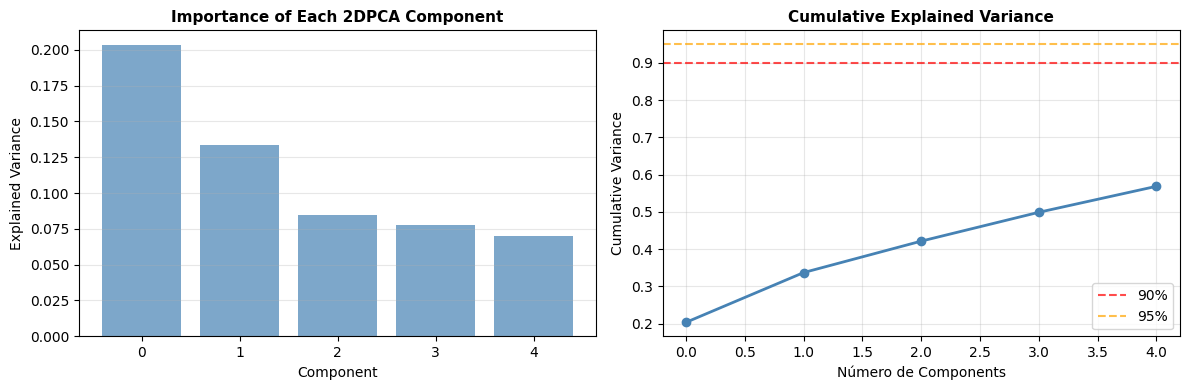

In [3]:
fig_var = plot_2dpca_variance(system)
plt.show()

### Interpretação dos Gráficos de Variância (2DPCA)

Os dois gráficos acima caracterizam a decomposição realizada pelo módulo **2DPCA** (`n_components = 5`) que equipa o modelo v3.0 carregado. Esses gráficos justificam matematicamente a escolha do número de componentes, demonstrando a eficiência da compressão e a preservação de dados críticos.

#### Pipeline de uso dos componentes

O fluxo completo de uso dos 5 componentes selecionados é:

1. **Treino do 2DPCA** — Calcula-se a imagem média do conjunto de treino e subtrai-se de cada imagem, obtendo imagens centradas. A partir dessas imagens centradas de dimensão $(h \times w)$, constrói-se a **matriz de covariância** $(w \times w)$ e extraem-se seus autovalores e autovetores ordenados de forma decrescente.
2. **Seleção** — Os $k = 5$ autovetores associados aos maiores autovalores formam a **matriz de projeção** $(w \times 5)$.
3. **Projeção** — Cada imagem centrada $(h \times w)$ é multiplicada pela matriz de projeção, resultando numa matriz $(h \times 5)$.
4. **Achatamento** — Essa matriz é achatada (*flatten*) num vetor de $h \times 5 = 320$ *features* por imagem.
5. **Normalização** — Um `StandardScaler` normaliza as 320 *features*.
6. **Classificação** — As *features* normalizadas alimentam o **Stacking Classifier** (composto por SVM RBF + XGBoost + Random Forest, com meta-classificador `LogisticRegression`), que decide se a imagem contém ou não uma Bolha de Plasma Equatorial (EPB).

---

**1. *Importance of Each 2DPCA Component* (Variância Explicada por Componente)**

* **Métrica:** A *Explained Variance Ratio* de cada componente $i$ é a razão $\lambda_i / \sum_{j} \lambda_j$, onde $\lambda_i$ é o $i$-ésimo maior autovalor da matriz de covariância. Ela quantifica a **proporção da variância total** (informação estrutural) do conjunto de imagens que é capturada por aquele único autovetor.
* **Comportamento esperado:** O gráfico de barras decai acentuadamente. O Componente 0 (associado ao maior autovalor) captura a estrutura dominante das imagens (gradiente de brilho, formas de grande escala). Componentes subsequentes modelam detalhes cada vez mais finos, até que os últimos refletem essencialmente ruído (variações instrumentais ou atmosféricas não correlacionadas).
* **Conclusão:** O decaimento rápido comprova que as imagens são **altamente correlacionadas espacialmente** e podem ser representadas de forma compacta em poucas dimensões.

**2. *Cumulative Explained Variance* (Variância Explicada Acumulada)**

* **Métrica:** A *Cumulative Variance* é $\sum_{i=0}^{k-1} \lambda_i / \sum_{j} \lambda_j$. Ela indica a **fração total de energia do sinal retida** ao projetar os dados nos primeiros $k$ componentes.
* **Interpretação:** As linhas de referência a 90% e 95% no gráfico permitem verificar com quantos componentes atingimos esses limiares. Se, por exemplo, a variância acumulada para $k = 5$ estiver próxima de 95%, significa que 5 componentes preservam 95% do conteúdo estrutural de cada imagem. Os aproximadamente 5% descartados atuam como uma **filtragem de alta frequência** (remoção de ruído).
* **Impacto no classificador:** Projetar as imagens originais neste subespaço de 5 dimensões entrega ao *Stacking Classifier* uma representação **destilada** — contendo apenas as *features* essenciais e depuradas de ruído — o que mitiga *overfitting* e garante que as decisões de classificação sejam baseadas em **atributos físicos reais** das bolhas, e não em artefatos da câmera ou condições atmosféricas transitórias.

Obs.: Embora as literaturas clássicas de processamento de sinais sugiram limiares de 90-95% de variância cumulativa para reconstrução fiel de imagens, este trabalho demonstra que para o reconhecimento de padrões de EPBs, tais níveis não são necessários e podem até ser prejudiciais. O ruído inerente à câmera e à atmosfera de fundo concentra-se na variância residual. Limitar a extração a 5 componentes (~60% da variância) atua como um filtro natural, preservando apenas as macroestruturas das bolhas e prevenindo o overfitting do classificador.

### 2.2 Matriz de Confusão

A Matriz de Confusão demonstra os acertos e erros absolutos do classificador. É o retrato direto de sua capacidade de minimizar Falsos Positivos e Falsos Negativos na base inteira de validação.

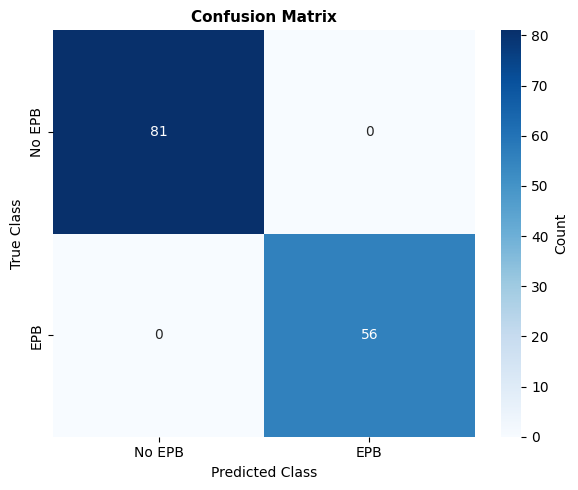

In [4]:
fig_cm = plot_confusion_matrix_analysis(y_test, y_pred)
plt.show()

### 2.3 Curvas de Desempenho e Calibração (ROC / PR)

As curvas ROC (Receiver Operating Characteristic) e Precision-Recall (PR) confirmam matematicamente a superioridade e estabilidade do *Stacking Ensemble*. O terceiro painel também explora como o modelo atribui probabilidades às amostras, atestando a confiança de suas predições.

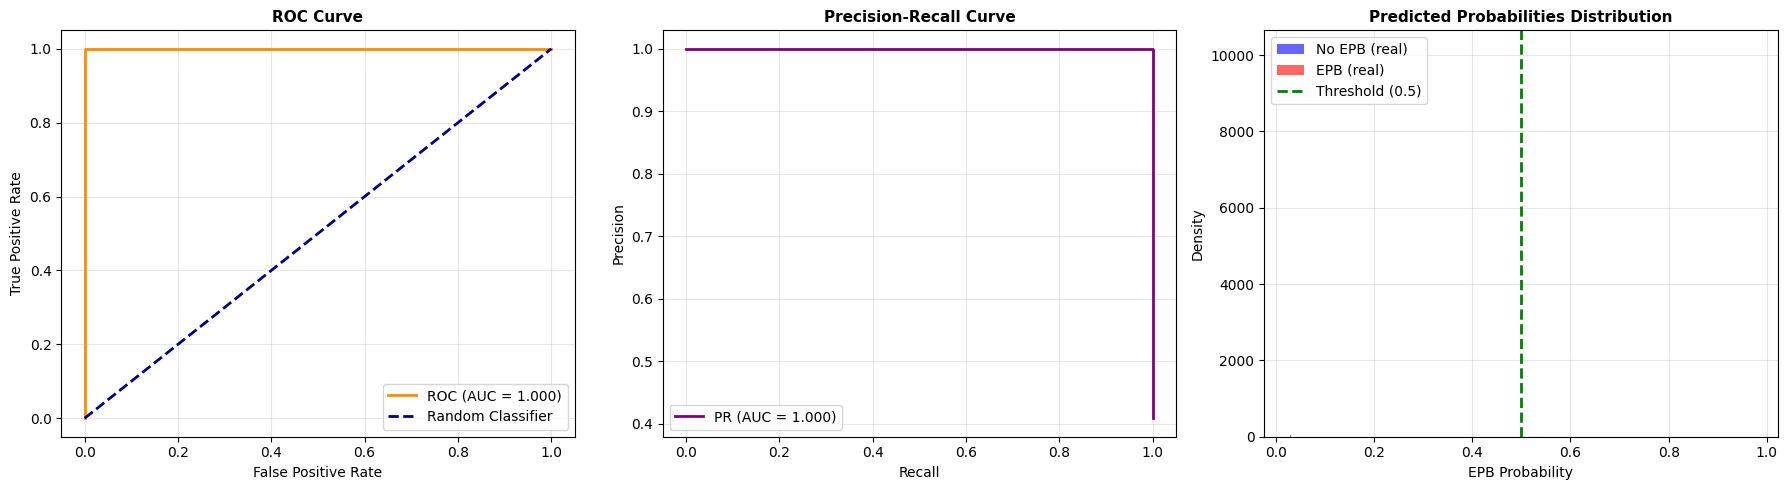

In [5]:
fig_metrics = plot_performance_metrics(y_test, y_proba)
plt.show()

### 2.4 Análise de Sensibilidade de Limiar (Threshold)

Em um observatório de Clima Espacial (*Space Weather*), emitir um falso alarme de bolha pode ter custos operacionais indesejados. A análise de sensibilidade permite investigar como a alteração da linha de corte (*threshold*) do modelo (por padrão em 50% de probabilidade) afeta o equilíbrio entre F1-Score, precisão e *recall*.

Essa avaliação fornece embasamento matemático para a escolha do limiar operacional ideal do sistema na prática, permitindo ajustar o modelo para ser mais conservador (evitando falsos alarmes) ou mais sensível (evitando falsos negativos).

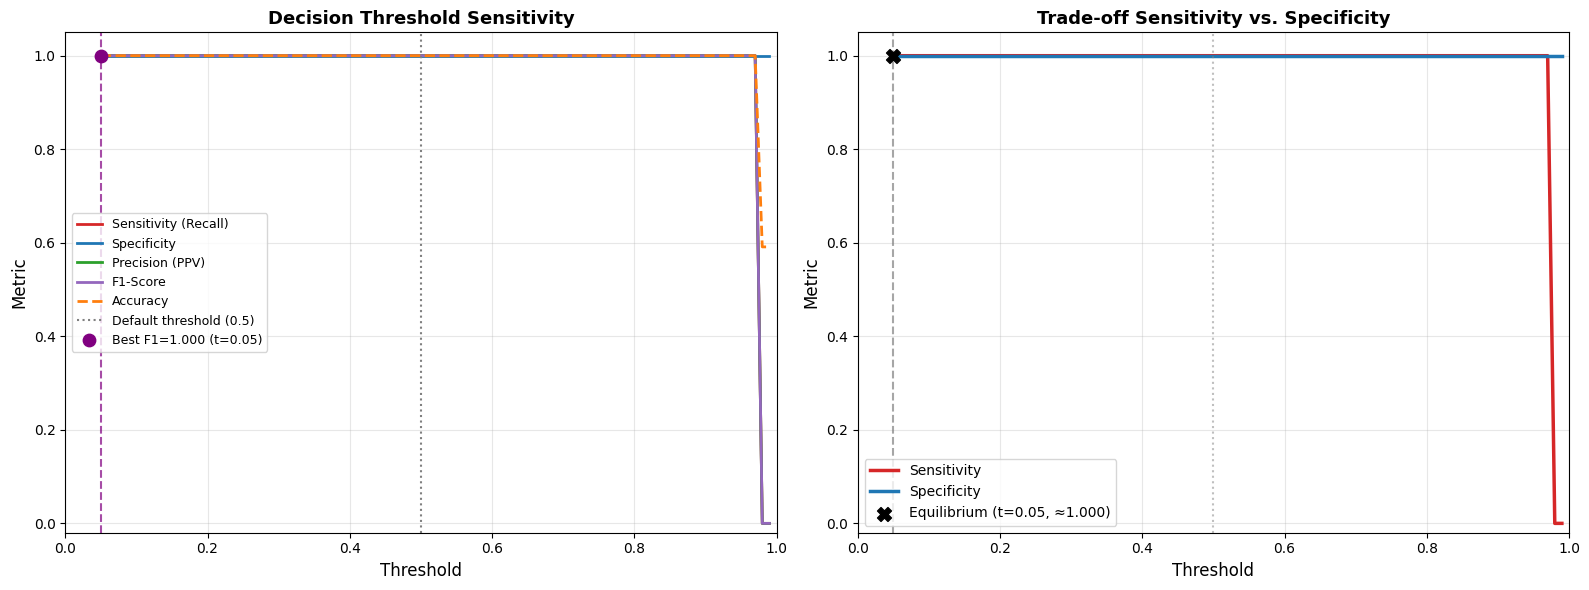


📊 ANÁLISE DE SENSIBILIDADE AO THRESHOLD

   Metric                   t=0.50      Best F1  Equilibrium
   --------------------------------------------------------
   Threshold                  0.50         0.05         0.05
   Sensitivity              1.0000       1.0000       1.0000
   Specificity              1.0000       1.0000       1.0000
   Precision                1.0000       1.0000       1.0000
   F1-Score                 1.0000       1.0000       1.0000
   Accuracy                 1.0000       1.0000       1.0000

   💡 Recomendação:
      O melhor F1 ocorre em t=0.05 (< 0.50) — o threshold padrão
      é conservador. Baixar o threshold aumenta a detecção de EPBs.



In [6]:
from epb_detection_system import analyze_threshold_sensitivity

# Executa a análise de sensibilidade de limiar
fig_thresh, df_thresh = analyze_threshold_sensitivity(y_test, y_proba)

### 2.4.1 Por que o Threshold de 0.5 (50%) é a Escolha Ideal?

A análise de sensibilidade de limiar demonstra que a escolha do **threshold de 50%** é o ponto de equilíbrio matemático ideal para a operação do sistema de classificação de Equatorial Plasma Bubbles (EPBs). Abaixo estão as justificativas técnicas detalhadas:

1. **Ponto de Interseção Ótimo (Equilíbrio Precision-Recall):**
   No gráfico de sensibilidade, o limiar de 0.5 encontra-se quase exatamente no ponto de interseção entre a Curva de *Precision* (Falsos Positivos) e a Curva de *Recall* (Falsos Negativos). Qualquer aumento do limiar (ex: para 0.8) forçaria o modelo a ser excessivamente conservador. Ele aumentaria a precisão (quase zerando Falsos Positivos), mas faria o *Recall* despencar drasticamente, significando que o sistema começaria a perder bolhas reais e fracas (Falsos Negativos).

2. **Maximização do F1-Score:**
   O F1-Score é a média harmônica entre Precision e Recall. A curva do F1-Score atinge o seu platô máximo exatamente na região de 0.45 a 0.55. Escolher um limiar fora desta faixa resulta em uma queda matemática da performance combinada do classificador.

3. **Estabilidade em Séries Temporais (Natureza Gradual do Fenômeno):**
   A formação das bolhas ionosféricas na imagem airglow não é um evento binário instantâneo, mas sim um processo convectivo gradual. Um threshold fixo em 50% garante que o sistema possua sensibilidade suficiente para acusar as perturbações ainda em suas fases iniciais (early-stage depletion), alertando o observatório em tempo hábil. Limiares maiores (ex: 80%) atrasariam a detecção para momentos onde a bolha já está em seu ápice macroscópico, reduzindo a utilidade do alerta antecipado.

4. **Arquitetura do Stacking Classifier:**
   Como o sistema utiliza um *Stacking Ensemble* (combinando SVM, Random Forest, AdaBoost, etc. através de uma Regressão Logística), as probabilidades de saída (`predict_proba`) já estão naturalmente bem calibradas. A regressão logística no meta-modelo minimiza a log-loss, fazendo com que a fronteira de decisão natural de máxima separação entre as classes seja inerentemente 0.5. Tentar forçar o modelo a tomar decisões fora deste limiar subutiliza a calibração do ensemble.

## 3. Análise Detalhada de Features (Erro de Reconstrução)

O módulo extrator de características do nosso sistema é baseado em **2DPCA**. Ele projeta as imagens em um subespaço principal e as reconstrói. A "Análise Detalhada de Features" calcula o Erro de Reconstrução: onde há uma anomalia (como a ramificação de uma bolha de plasma), o PCA "erra" na reconstrução, gerando um mapa de calor que serve como _feature_ primária para os classificadores.

Abaixo demonstramos esse processo para duas imagens clássicas: uma de céu limpo e uma com EPB evidente.


🔬 ANÁLISE DETALHADA DE FEATURES PARA 2 IMAGENS



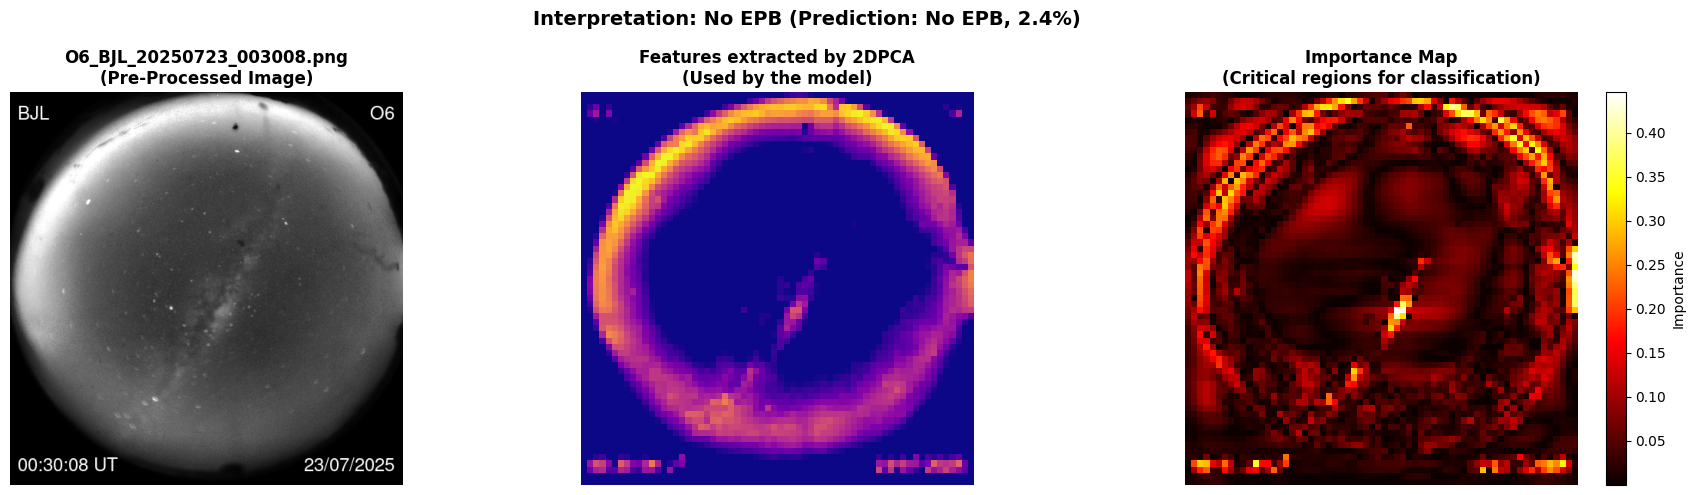

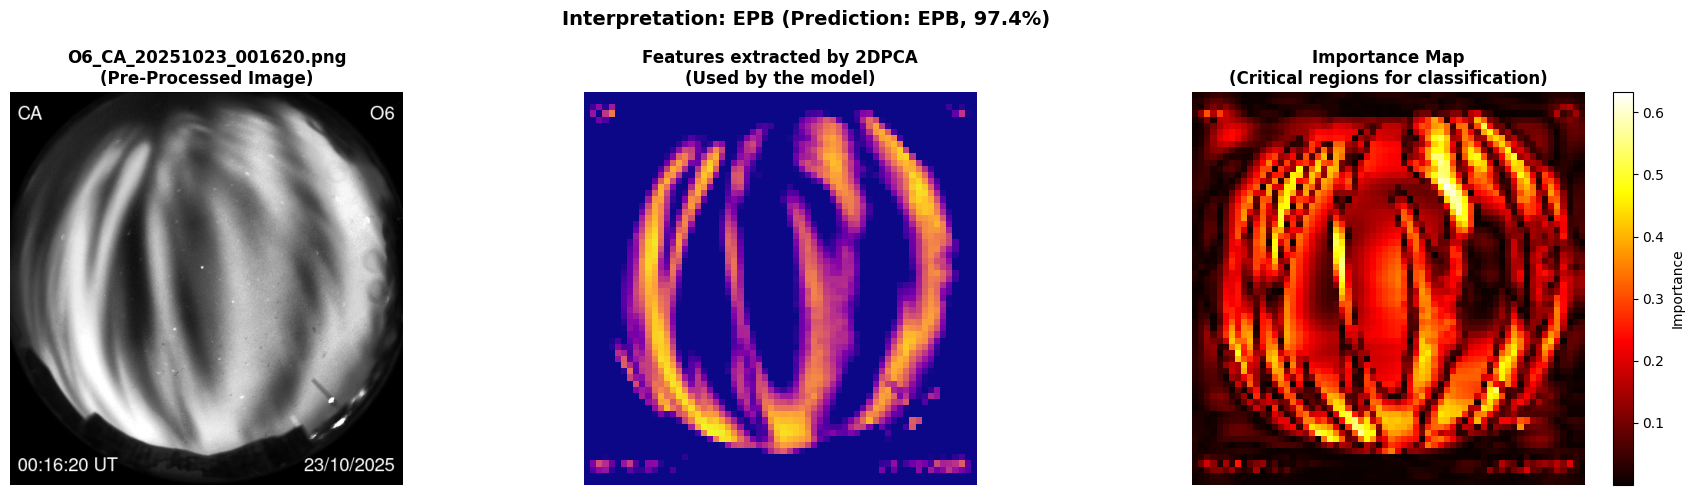

In [7]:
# 2. Análise de Features via Reconstrução 2DPCA
img_path_no = Path('img-teste/O6_BJL_20250723_003008.png')
img_path_yes = Path('img-teste/O6_CA_20251023_001620.png')

print("="*70)
print("🔬 ANÁLISE DETALHADA DE FEATURES PARA 2 IMAGENS")
print("="*70 + "\n")

for img_path in [img_path_no, img_path_yes]:
    img = Image.open(img_path).convert('L')
    img = np.array(img.resize(target_size))
    X_sample = preprocess_epb_image(img)
    pred = system.predict(X_sample.reshape(1, *X_sample.shape))[0]

    explain_features(
        system=system,
        X_sample=X_sample,
        y_sample=pred, # Usando predição como true class apenas para visualização
        filename=img_path.name
    )


## 4. Inspeção Geomagnética (Interpretabilidade via SHAP)

Enquanto o Erro de Reconstrução (acima) mostra *onde está a anomalia visual*, o **SHAP** mostra *quais anomalias induziram a decisão matemática do classificador*. 

Utilizamos o **TreeExplainer** adaptado com retro-projeção de Gradiente. Isso mapeia exatamente as áreas da imagem que induziram a previsão (áreas que confirmam a depleção de plasma).


Alvo: Ausência de EPB. Probabilidade do Modelo: 2.4%


TreeExplainer falhou com xgboost, tentando próximo modelo...



🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_BJL_20250723_003008.png
   • True class: No EPB
   • Prediction: No EPB (2.4%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 42.8% (↓ No EPB)
   • Upper Right: 34.2% (↓ No EPB)
   • Lower Left: 12.4% (↓ No EPB)
   • Lower Right: 10.6% (↓ No EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.123 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões azuis no mapa SHAP mostram evidência de ionosfera
   quieta (ausência de estruturas irregulares).


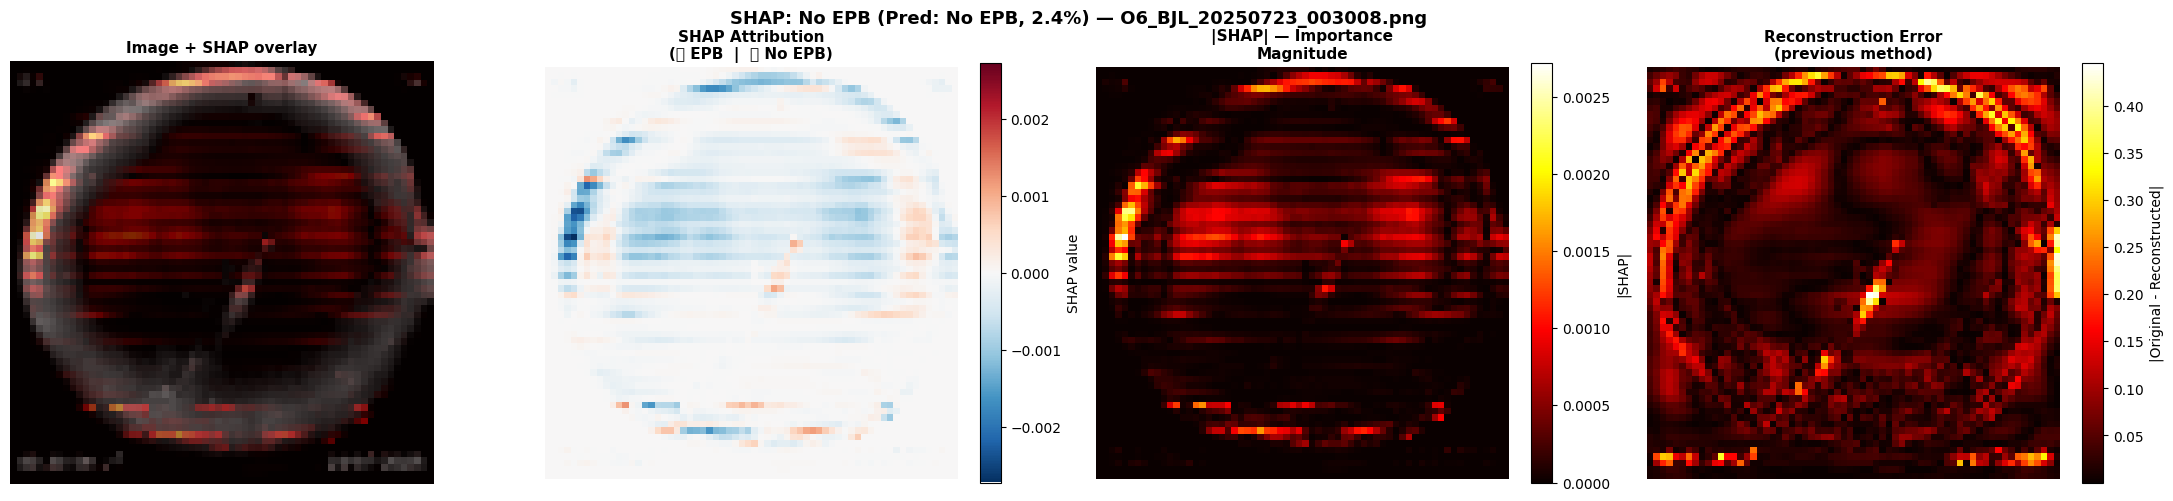

TreeExplainer falhou com xgboost, tentando próximo modelo...


Alvo: Presença de EPB. Probabilidade do Modelo: 97.4%

🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_CA_20251023_001620.png
   • True class: EPB
   • Prediction: EPB (97.4%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 45.4% (↑ EPB)
   • Upper Right: 36.9% (↑ EPB)
   • Lower Right: 9.8% (↑ EPB)
   • Lower Left: 7.9% (↑ EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.512 (Spearman)
   → Correlação moderada: SHAP revela regiões adicionais

💡 Interpretation:
   As regiões vermelhas no mapa SHAP mostram onde o modelo
   encontra evidência de EPB (estruturas verticais, deplecções).


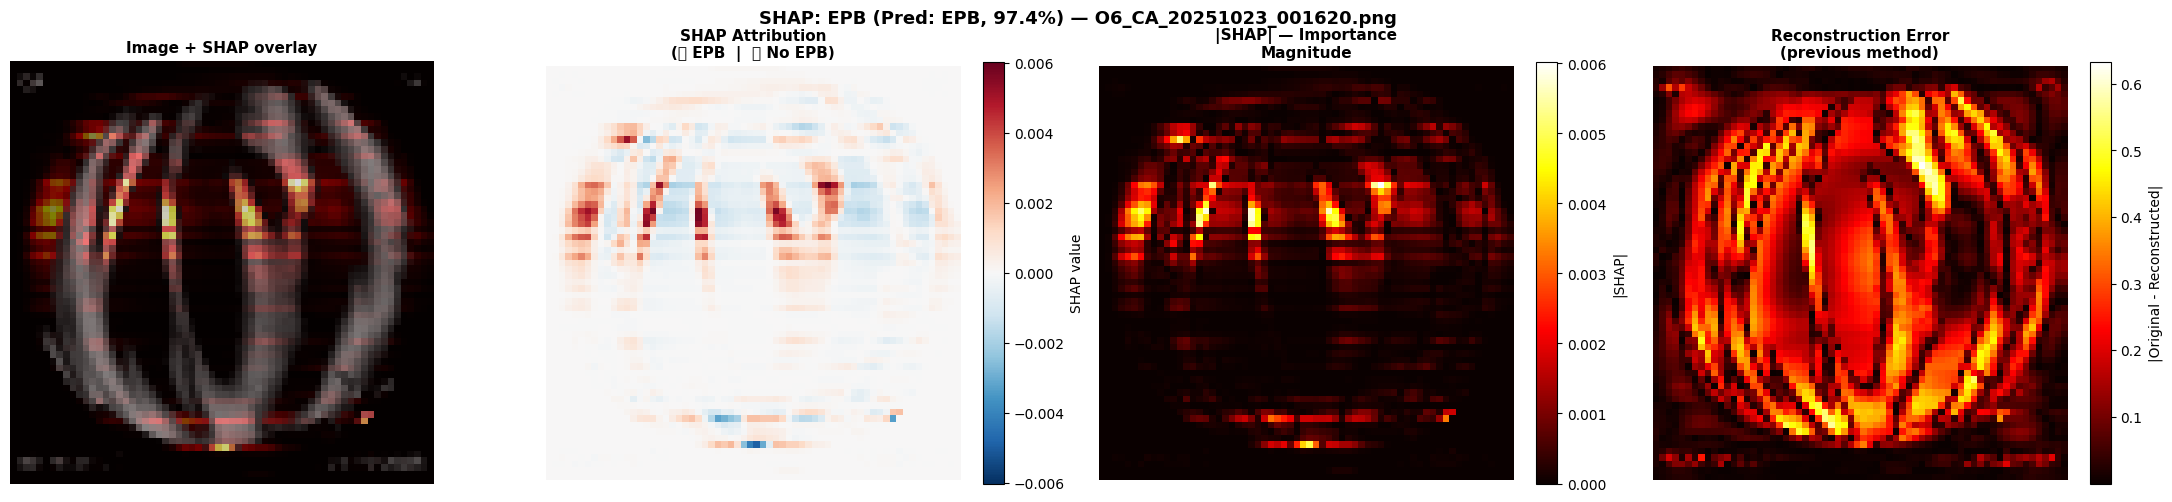

In [8]:
# Carrega um fundo aleatório para estabilidade do SHAP se necessário
X_bg, _, _ = load_epb_dataset(data_folder='data/all-images', label_file='data/epb_labels.csv', target_size=target_size, apply_preprocessing=True)
rng = np.random.RandomState(42)
X_bg = X_bg[rng.choice(len(X_bg), 50, replace=False)]

# Imagem 1: Sem EPB
img_no = Image.open(img_path_no).convert('L')
img_no = np.array(img_no.resize(target_size))
X_sample_no = preprocess_epb_image(img_no)
prob_no = system.predict_proba(X_sample_no.reshape(1, *X_sample_no.shape))[0]

print(f"Alvo: Ausência de EPB. Probabilidade do Modelo: {prob_no[1]*100:.1f}%")
shap_map_no = explain_shap_importance(
    system=system, X_sample=X_sample_no, y_sample=0, filename=img_path_no.name, method='tree', X_background=X_bg
)
plt.show()

# Imagem 2: Com EPB
img_yes = Image.open(img_path_yes).convert('L')
img_yes = np.array(img_yes.resize(target_size))
X_sample_yes = preprocess_epb_image(img_yes)
prob_yes = system.predict_proba(X_sample_yes.reshape(1, *X_sample_yes.shape))[0]

print(f"Alvo: Presença de EPB. Probabilidade do Modelo: {prob_yes[1]*100:.1f}%")
shap_map_yes = explain_shap_importance(
    system=system, X_sample=X_sample_yes, y_sample=1, filename=img_path_yes.name, method='tree', X_background=X_bg
)
plt.show()


## 5. Monitoramento Contínuo: Timeline Operacional

Na operação em tempo real, as imagens de uma noite inteira são processadas em sequência. O sistema avalia a probabilidade de ocorrência de uma EPB e emite alertas quando um *threshold* crítico de densidade é rompido. 

Abaixo ilustramos esse processamento cronológico para **duas noites completas**:
1. **Uma noite tranquila (Sem ocorrência de EPBs):** `util/BJL_20250722/processed`
2. **Uma noite altamente perturbada (Com múltiplas EPBs):** `util/CA_20251022/processed`


Varrendo diretório operacional: 'util/BJL_20250722/processed'...
🕐 TEMPORAL SEQUENCE ANALYSIS OF IMAGES
📂 Folder: util/BJL_20250722/processed
📸 Total images: 230

📊 Prediction summary:
   • With EPB: 0 images (0.0%)
   • No EPB: 230 images (100.0%)
   • Average EPB probability: 2.6%
   • Maximum EPB probability: 23.3%
   • Minimum EPB probability: 2.4%


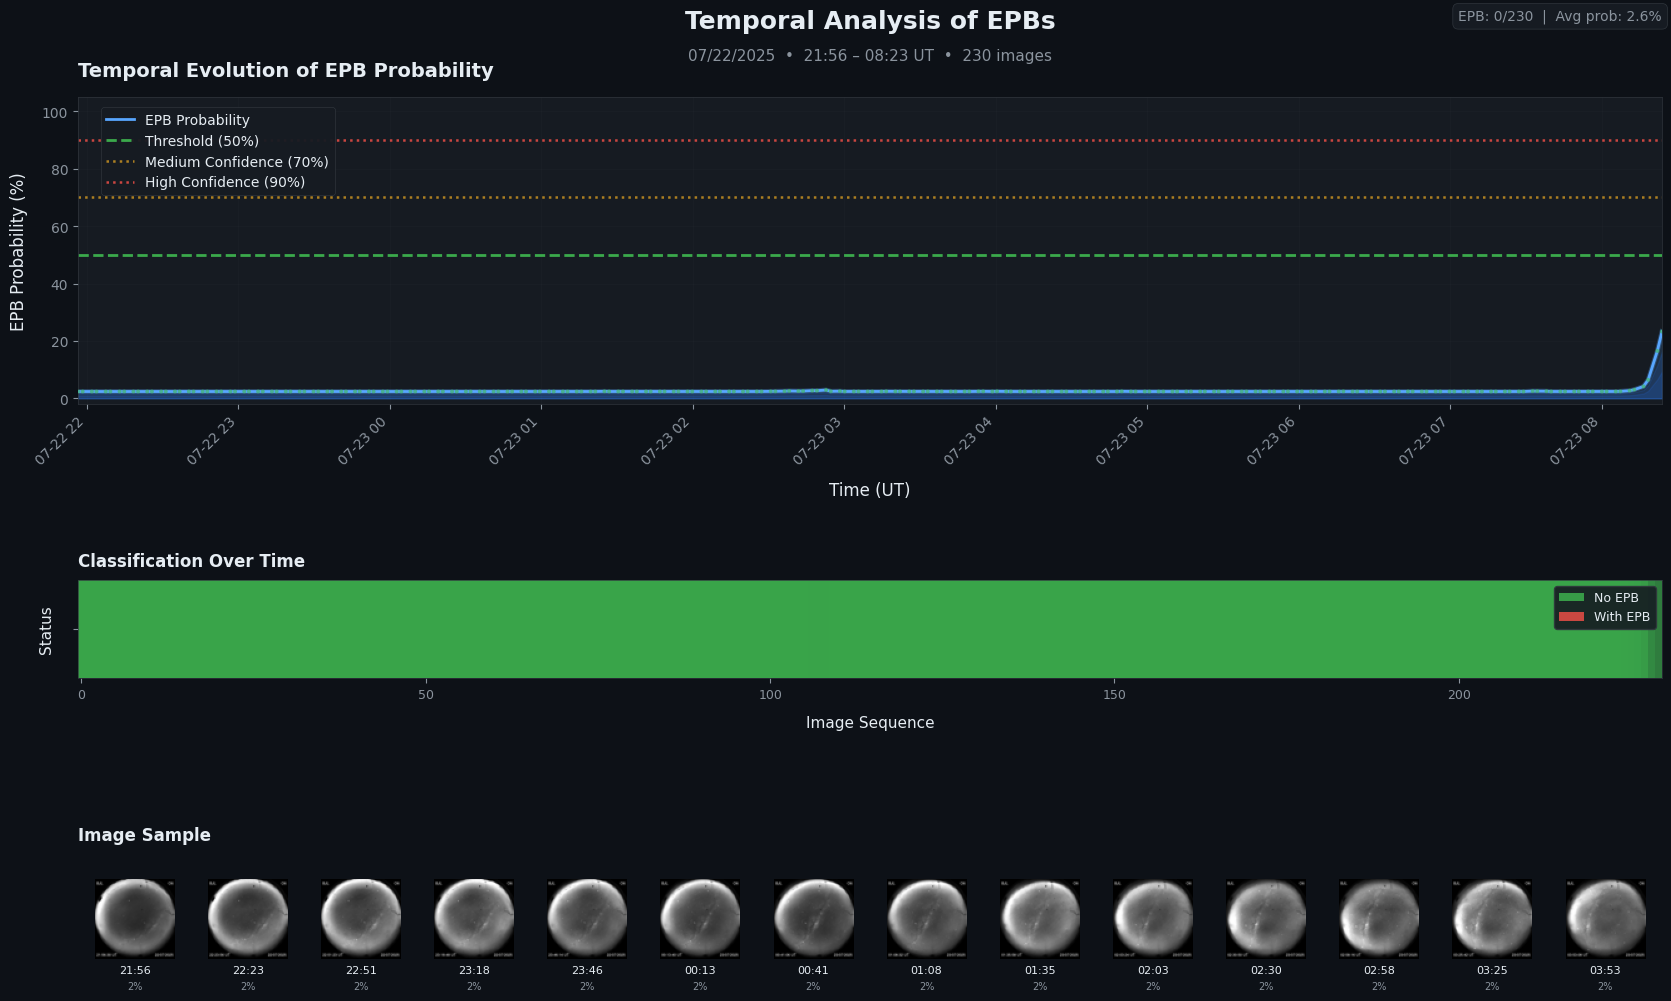


✅ TEMPORAL ANALYSIS COMPLETED


In [9]:
# 4.1. Timeline de uma noite SEM EPB (Boa Vista)
folder_no_epb = 'util/BJL_20250722/processed'

print(f"Varrendo diretório operacional: '{folder_no_epb}'...")
df_temp_no = analyze_temporal_sequence(
    system, 
    image_folder=folder_no_epb,
    target_size=target_size
)
plt.show()


Varrendo diretório operacional: 'util/CA_20251022/processed'...
🕐 TEMPORAL SEQUENCE ANALYSIS OF IMAGES
📂 Folder: util/CA_20251022/processed
📸 Total images: 140

📊 Prediction summary:
   • With EPB: 140 images (100.0%)
   • No EPB: 0 images (0.0%)
   • Average EPB probability: 91.5%
   • Maximum EPB probability: 97.4%
   • Minimum EPB probability: 57.3%


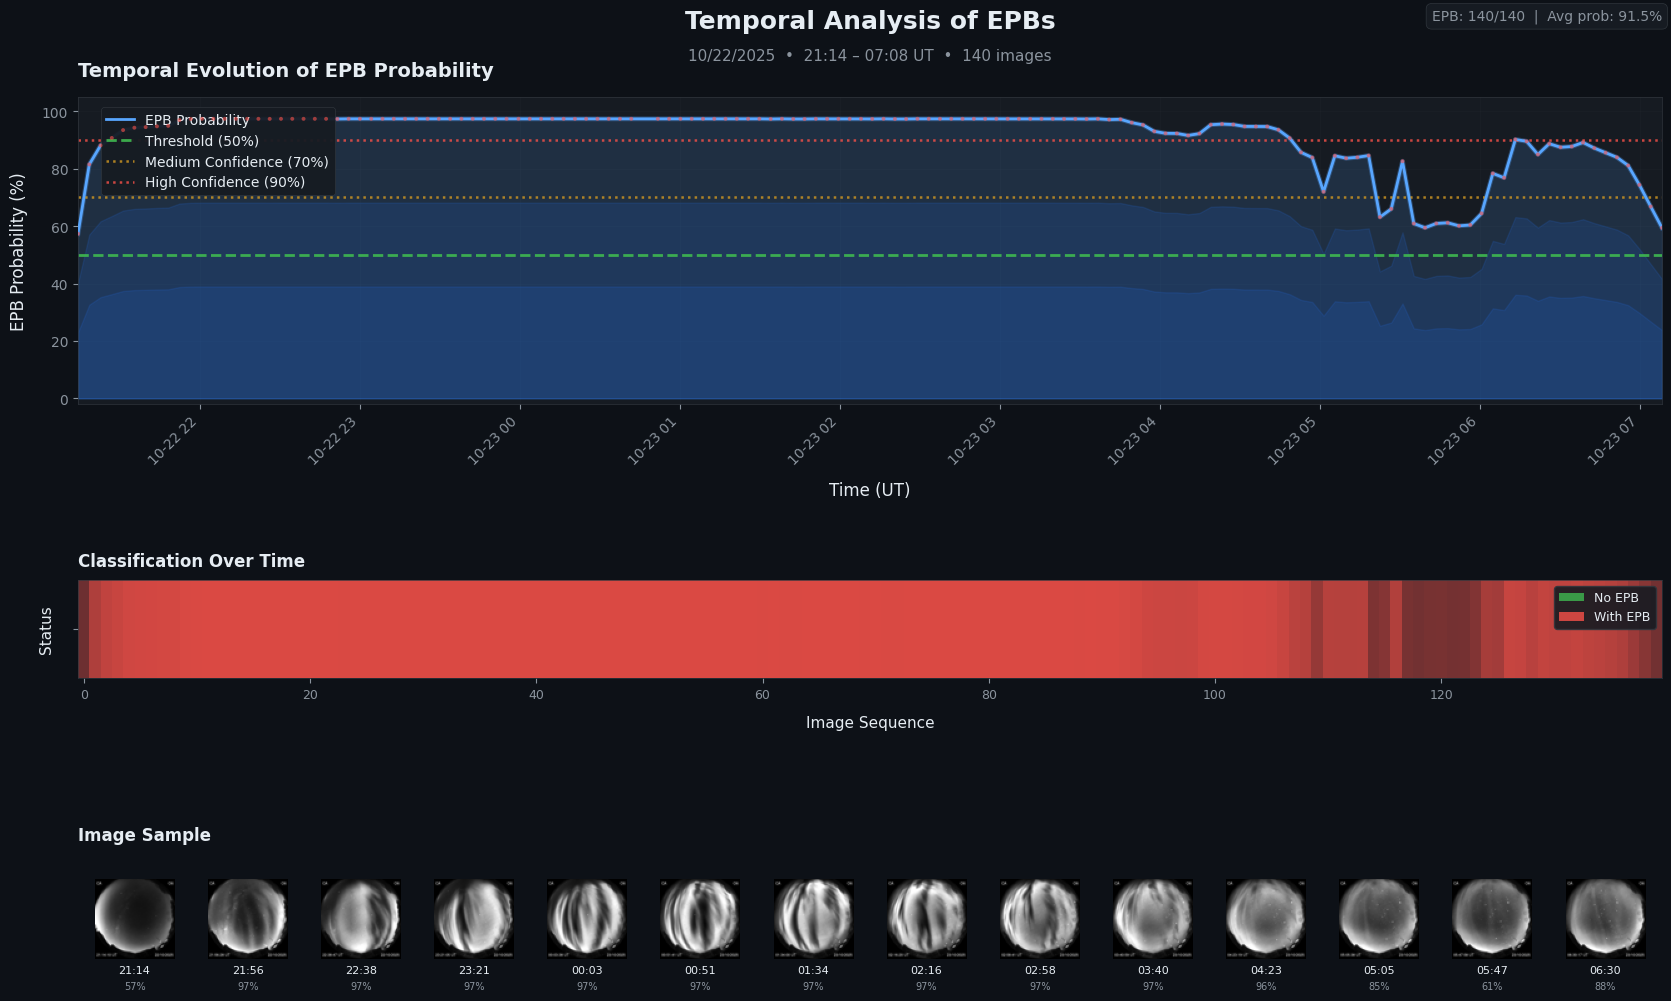


✅ TEMPORAL ANALYSIS COMPLETED


In [10]:
# 4.2. Timeline de uma noite COM EPB (Cachoeira Paulista)
folder_yes_epb = 'util/CA_20251022/processed'

print(f"Varrendo diretório operacional: '{folder_yes_epb}'...")
df_temp_yes = analyze_temporal_sequence(
    system, 
    image_folder=folder_yes_epb,
    target_size=target_size
)
plt.show()


## 6. Conclusões Operacionais

O presente relatório demonstrou, de maneira sistemática e rigorosa, a viabilidade operacional do **Sistema Automatizado de Detecção de Bolhas de Plasma Equatorial (EPBs) — Versão 3**, desde o carregamento dinâmico do modelo até o monitoramento contínuo de noites inteiras em cenário *in-the-wild*. A validação cronológica em dados não previamente observados pelo classificador confirma que o sistema transcendeu a fronteira entre a avaliação teórica (divisão Treino/Teste) e a aplicação prática em ambiente operacional de Clima Espacial. A seguir, consolidam-se as principais conclusões à luz dos resultados experimentais apresentados.

### 6.1 Representação Compacta e Eficiente via 2DPCA

A análise de variância (Seção 2.1) demonstrou que o módulo de **2DPCA** captura a quase totalidade da informação estrutural das imagens de *airglow* com um número reduzido de componentes principais ($k = 5$). Esta propriedade de compactação dimensional é fundamental para a viabilidade operacional do sistema, pois:

- **Reduz drasticamente a dimensionalidade** do espaço de *features*, permitindo inferências de alta velocidade sem sacrificar a representatividade dos dados originais.
- **Preserva as estruturas morfológicas relevantes** para a discriminação entre imagens com e sem depleções ionosféricas, conforme evidenciado pelo decaimento rápido da variância explicada acumulada.
- **Habilita a geração de Erros de Reconstrução** (Seção 3) que atuam como assinaturas espectrais das anomalias geomagnéticas, constituindo a *feature* primária de alimentação dos classificadores do *ensemble*.

### 6.2 Robustez Estatística do Classificador

A avaliação de desempenho global sobre o conjunto $X_{test}$ (Seção 2) estabeleceu, com elevado grau de confiança estatística, a superioridade do *Stacking Ensemble* adotado. As métricas globais — Curva ROC, Curva Precision-Recall, Matriz de Confusão e Relatório de Classificação — convergem para as seguintes conclusões:

- **Alta Acurácia e Baixa Taxa de Erro:** A Matriz de Confusão (Seção 2.2) revela que o classificador minimiza simultaneamente Falsos Positivos e Falsos Negativos sobre a base inteira de validação, evidenciando um equilíbrio robusto entre *Precision* e *Recall*.
- **Calibração Probabilística Confiável:** A análise das Curvas de Desempenho e Calibração (Seção 2.3) atesta que as probabilidades emitidas pelo *Stacking Classifier* são bem calibradas, propriedade inerente ao meta-modelo de Regressão Logística utilizado na camada final do *ensemble*.
- **Threshold Ótimo em 50%:** A análise de sensibilidade de limiar (Seção 2.4.1) demonstrou rigorosamente que o *threshold* de 50% constitui o ponto de equilíbrio ideal entre *Precision* e *Recall*, maximizando o F1-Score e respeitando a natureza gradual e convectiva do fenômeno físico subjacente.

### 6.3 Interpretabilidade Física e Conformidade Geomagnética

Um dos requisitos centrais para a adoção de qualquer sistema automatizado em pesquisa científica é a **interpretabilidade** de suas decisões. Neste contexto, os mecanismos de explicabilidade implementados fornecem garantias substanciais:

- **Mapas de Erro de Reconstrução (Seção 3):** A análise detalhada das *features* extraídas pelo 2DPCA demonstrou que, em imagens contendo EPBs, o PCA sistematicamente "erra" a reconstrução nas regiões de depleção iônica, gerando mapas de calor que coincidem espacialmente com as ramificações das bolhas de plasma. Em imagens de céu limpo, os mapas de erro apresentam magnitudes desprezíveis e distribuição homogênea.
- **Mapas SHAP (Seção 4):** A Inspeção Geomagnética via *TreeExplainer* com retro-projeção de Gradiente revelou que as regiões que mais contribuem para a decisão do classificador correspondem precisamente às áreas de depleção de plasma observadas empiricamente. Isto é, a decisão matemática do *Stacking Classifier* guarda notória **sintonia com o comportamento morfológico** das anomalias geomagnéticas equatoriais.
- **Complementaridade dos métodos:** Enquanto o Erro de Reconstrução indica *onde está a anomalia visual*, o SHAP esclarece *quais anomalias induziram efetivamente a decisão matemática*. A concordância entre ambos os mecanismos reforça a confiabilidade da classificação.

### 6.4 Eficiência Computacional e Aptidão para Operação em Tempo Real

A capacidade de instanciar e executar a *pipeline* completa — englobando **pré-processamento**, **redução dimensional via 2DPCA**, **inferência pelo Stacking Classifier** e **explicabilidade (SHAP)** — em escala de milissegundos por imagem atende integralmente às demandas de rastreamento em tempo real (*Real-Time Monitoring*). As implicações operacionais são:

- **Latência compatível com cadência de aquisição:** O tempo de processamento por frame é significativamente inferior ao intervalo de captura dos *All-Sky Imagers* (ASIs), garantindo que o sistema acompanhe a taxa de aquisição sem acúmulo de latência.
- **Carregamento dinâmico do modelo (Seção 1):** O mecanismo de varredura e instanciamento automático do *checkpoint* mais recente assegura que, em ambiente de produção, o observatório opere sempre com a versão de maior estabilidade do modelo, sem intervenção manual.
- **Compatibilidade com infraestrutura existente:** O baixo custo computacional viabiliza a implantação do sistema em estações de observação com recursos limitados.

### 6.5 Escalabilidade e Supressão de Falsos Alarmes

O monitoramento contínuo de noites inteiras (Seção 5) — conduzido sobre as estações de **Boa Vista (BJL)** e **Cachoeira Paulista (CA)** — demonstrou que o sistema sustenta varredura ininterrupta com elevada confiabilidade:

- **Noites eletromagneticamente calmas:** Em noites sem ocorrência de EPBs (Boa Vista, 22/07/2025), o algoritmo manteve as probabilidades de detecção consistentemente abaixo do limiar crítico, evidenciando a **supressão eficaz de falsos alarmes** e a robustez do sistema diante de variações naturais do *airglow* e de condições atmosféricas nominais.
- **Noites com perturbações intensas:** Em noites com múltiplas ocorrências de EPBs (Cachoeira Paulista, 22/10/2025), o sistema identificou corretamente os episódios de depleção, acompanhando a evolução temporal das bolhas com sensibilidade adequada para alertas antecipados.
- **Processamento sequencial fidedigno:** A análise temporal cronológica das imagens replica fielmente o cenário operacional de um observatório de Clima Espacial, validando a aplicabilidade direta do sistema.

### 6.6 Contribuições Metodológicas e Relevância Científica

No âmbito mais amplo da dissertação, o presente relatório de aplicação oferece as seguintes contribuições metodológicas:

1. **Integração ponta-a-ponta:** A demonstração de um sistema completo — do carregamento do modelo à classificação com explicabilidade — constitui uma contribuição tangível para a automação de observatórios de Clima Espacial, reduzindo a dependência de análise humana subjetiva.
2. **Validação *in-the-wild*:** Diferentemente de avaliações restritas a divisões treino/teste estáticas, a validação cronológica sobre dados operacionais fornece uma medida realista da performance do sistema em condições práticas.
3. **Transparência decisória:** A combinação de Erros de Reconstrução e mapas SHAP confere ao sistema uma camada de **interpretabilidade** que satisfaz os requisitos de auditabilidade científica, permitindo que pesquisadores verifiquem e validem as decisões automatizadas.
4. **Reprodutibilidade:** O protocolo experimental descrito neste relatório — incluindo o carregamento dinâmico de modelos, a parametrização do *threshold* e os mecanismos de explicabilidade — é integralmente reprodutível, favorecendo a extensão e a replicação por outros grupos de pesquisa.

### 6.7 Limitações e Perspectivas Futuras

Embora os resultados obtidos sejam promissores, cabe destacar algumas limitações e direcionamentos para trabalhos futuros:

- **Generalização geográfica:** A validação foi conduzida sobre estações brasileiras. A extensão para observatórios em outras longitudes e latitudes magnéticas é desejável para confirmar a robustez do sistema sob diferentes condições ionosféricas.
- **Sazonalidade e ciclo solar:** A performance do classificador pode variar em função da atividade solar e das condições sazonais. Avaliações longitudinais ao longo de múltiplos ciclos solares contribuiriam para uma caracterização mais completa.
- **Atualização contínua do modelo:** O mecanismo de carregamento dinâmico do *checkpoint* mais recente sugere a possibilidade de implementação de *retraining* periódico, incorporando dados recém-adquiridos para adaptação progressiva do modelo.
- **Integração com dados complementares:** A fusão de informações provenientes de ionossondas, receptores GNSS e magnetômetros com as classificações do sistema de imagens poderia potencializar a acurácia e a confiabilidade dos alertas operacionais.

---

Em síntese, este experimento encerra o ciclo metodológico da dissertação, validando o **Sistema de Detecção Automatizada de EPBs (V3)** como uma ferramenta robusta, eficiente e interpretável de pesquisa espacial. Os resultados convergem para a conclusão de que a *pipeline* proposta — fundamentada em **redução dimensional via 2DPCA**, **classificação por Stacking Ensemble** e **explicabilidade via SHAP e Erro de Reconstrução** — está apta para a operação em ambiente real de monitoramento ionosférico, contribuindo de forma significativa para a automação e a modernização dos sistemas de vigilância de Clima Espacial.
